# 02. Градиентный бустинг

**Идея.** Случайный лес строит много *независимых* глубоких деревьев и усредняет их. Градиентный бустинг устроен наоборот:
деревья мелкие и строятся **по очереди**, каждое исправляет ошибки уже построенных. Модель — сумма
$a(x) = a_0 + \eta\,(b_1(x) + b_2(x) + \dots + b_T(x))$, где $\eta$ — темп обучения. Каждое новое дерево $b_t$ обучается
предсказывать **антиградиент** потерь по текущим ответам модели («псевдоостатки»), то есть направление, в котором надо
сдвинуть ответ, чтобы потери уменьшились. От выбора потерь зависит, на что «смотрят» деревья:

| потери | антиградиент (что предсказывает дерево) | поведение |
|:--|:--|:--|
| логистические (log-loss) | $y - p(x)$ | вероятностная модель классов, стандарт для классификации |
| квадратичные | $y - a(x)$ | чувствительны к выбросам |
| абсолютные (MAE) | $\mathrm{sign}(y - a(x))$ | устойчивы к выбросам, шаг не зависит от размера ошибки |
| Хьюбера | $y - a$, если $\lvert y - a\rvert \le \delta$, иначе $\delta\,\mathrm{sign}(y - a)$ | квадрат для малых ошибок, модуль для больших |

Бустинг, в отличие от леса, **переобучается с ростом числа деревьев**, поэтому число деревьев и темп обучения подбираются вместе.

Порядок: (1) три бустинга по умолчанию как точка отсчёта, (2) случайный поиск параметров на кросс-валидации для каждого
и общий график подбора, (3) выбор числа деревьев и влияние темпа обучения, (4) итог и сохранение, (5) важность признаков,
(6) test — один раз в самом конце.

Бустинги в ноутбуке: `HistGradientBoosting` (гистограммный, как в LightGBM), `GradientBoosting` из sklearn (точные разбиения,
log-loss) и **CatBoost**.

Данные, разбиение и блоки CV — те же, что у старых моделей (первая ячейка).

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import boosting_utils as bu                         # BalancedFit: лежит рядом с solution_utils.py
import solution_utils as su
from solution_utils import CLASSES, SEED

NO_COLOR = ("std", "доля", "param_", "деревьев", "шаг", "проба")        # столбцы без заливки
LOWER_IS_BETTER = ("time", "время", "loss", "error", "mae", "rmse")      # для них лучше меньшее значение


def show_table(frame, digits=3, axis=0):
    """Таблица с заливкой. Устойчива к неуникальным индексам/колонкам и к падению Styler.

    - Если индекс или колонки не уникальны — сбрасываем индекс и дедуплицируем колонки.
    - Если Styler всё равно не может отрисовать — возвращаем обычный DataFrame.
    """
    df = frame.copy()

    # 1) Чиним неуникальный индекс
    if not df.index.is_unique:
        df = df.reset_index(drop=True)

    # 2) Чиним неуникальные колонки
    if not df.columns.is_unique:
        seen = {}
        new_cols = []
        for c in df.columns:
            if c in seen:
                seen[c] += 1
                new_cols.append(f"{c}_{seen[c]}")
            else:
                seen[c] = 0
                new_cols.append(c)
        df.columns = new_cols

    numeric = list(df.select_dtypes("number").columns)
    plain = [c for c in numeric if any(k in str(c) for k in NO_COLOR)]
    lower = [c for c in numeric if c not in plain and any(k in str(c) for k in LOWER_IS_BETTER)]
    higher = [c for c in numeric if c not in plain and c not in lower]

    try:
        styled = df.style.format(precision=digits, subset=numeric)
        if higher:
            styled = styled.background_gradient(cmap="Greens", subset=higher, axis=axis)
        if lower:
            styled = styled.background_gradient(cmap="Greens_r", subset=lower, axis=axis)
        return styled
    except (KeyError, ValueError) as exc:
        # Styler не смог — отдаём обычный DataFrame, чтобы ноутбук не падал
        print(f"[show_table] Styler не смог отрисовать таблицу ({exc}); показываю без стилей.")
        return df


# Задача 1 из HW1: диалоги с use_reaction == 1 (флаги из dialog_flags.csv), разбиение по group_id
task1 = su.load_task1(su.train_path(), su.flags_path())
train_df, test_df = su.split_task1(task1)          # то же train/test, что в HW1

train_dialogs = train_df[["dialog_id", "turns"]].to_dict("records")
test_dialogs = test_df[["dialog_id", "turns"]].to_dict("records")
y_train, y_test = train_df["reaction"].to_numpy(), test_df["reaction"].to_numpy()
folds = su.get_folds(y_train, train_df["group_id"].to_numpy())   # одни блоки CV для всех моделей

print(f"всего для задачи 1: {len(task1)} | train: {len(train_df)} | test: {len(test_df)}")
show_table(pd.DataFrame({"доля train": pd.Series(y_train).value_counts(normalize=True),
                         "доля test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES])

всего для задачи 1: 2930 | train: 2344 | test: 586


,доля train,доля test
negative,0.308,0.305
neutral,0.593,0.606
positive,0.098,0.089


## Признаки для дерева

`make_frame` превращает диалог в таблицу: тексты пользователя (все реплики и последняя) и числа. Часть чисел — это флаги из
вашего EDA (код в репликах, зацикливание ассистента), посчитанные по репликам: так они работают и на скрытом тесте, где файла
флагов нет. Деревьям такие готовые числа нужны, длину текста дерево само не посчитает.

Отличие от леса: бустингам (кроме CatBoost, который умеет работать с текстом сам) нужна **плотная** матрица, а TF-IDF разрежен
и содержит тысячи почти всегда нулевых столбцов. Поэтому после TF-IDF стоит **SVD** (LSA): тысячи слов сжимаются
до 100 плотных «тем». Так признаки у всех бустингов одинаковые, и их можно честно сравнивать.

In [5]:
su.make_frame(train_dialogs[:3])

,user_text,last_user,n_user_turns,n_turns,user_chars_total,last_user_chars,max_user_chars,user_chars_mean,assistant_chars_mean,n_question_marks,n_exclamations,has_user_code,has_assistant_code,has_assistant_loop
0,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...","any spec symbols used in ""paradoxical arithmet...",7,14,8459,78,7924,1208.428571,1498.857143,12,5,0,0,0
1,Can you help me train a small language model t...,Give me GUI for this portion,8,16,1285,28,407,160.625000,4031.875000,1,0,0,1,0
2,ask questions about a fictional voice actor i ...,1.Alex was at the supermarket when a fan bumpe...,5,10,3330,1484,1596,666.000000,2387.600000,0,0,0,0,0


## Модель: `Pipeline`

Всё склеено в один объект, чтобы при кросс-валидации TF-IDF и SVD обучались только на обучающих блоках (иначе в признаки утечёт
проверочный блок). Три модели отличаются только последним шагом `gb`:

- `TfidfVectorizer` → `TruncatedSVD` — текст в плотные числа (отдельно для всех реплик и для последней);
- `"passthrough"` — числовые колонки идут как есть;
- `class_weight="balanced"` (у `GradientBoosting` — обёртка `BalancedFit`, у CatBoost — `auto_class_weights="Balanced"`) —
  редкие классы (positive всего ~10%) получают больший вес;
- `memory=CACHE_DIR` — `Pipeline` запоминает обученные признаки: при подборе параметров одни и те же блоки не пересчитываются
  заново для каждой пробы (папку `results/_cache` можно удалять).

In [6]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from catboost import CatBoostClassifier              # pip install catboost

CACHE_DIR = "results/_cache"

# ключ -> (название в таблицах, имя сохраняемой модели)
MODELS = {
    "hgb": ("HistGradientBoosting", "hw2_gb_hist"),
    "gbc": ("GradientBoosting (sklearn)", "hw2_gb_sklearn"),
    "catboost": ("CatBoost", "hw2_gb_catboost"),
}
# как к параметру модели обратиться через Pipeline (имена вида шаг__параметр; у обёртки BalancedFit есть вложенный шаг)
PREFIX = {"hgb": "gb__", "gbc": "gb__estimator__", "catboost": "gb__"}
# как в каждой модели называется число деревьев
TREES = {"hgb": "max_iter", "gbc": "n_estimators", "catboost": "iterations"}


def build_features():
    return ColumnTransformer([
        ("all_tfidf", Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=3000)),
                                ("svd", TruncatedSVD(n_components=100, random_state=SEED))]), "user_text"),
        ("last_tfidf", Pipeline([("tfidf", TfidfVectorizer(min_df=3, max_features=1000)),
                                 ("svd", TruncatedSVD(n_components=20, random_state=SEED))]), "last_user"),
        ("numeric", "passthrough", su.NUMERIC_COLUMNS),
    ])


def build_classifier(kind):
    if kind == "hgb":                                  # гистограммный: значения признаков сначала разбиваются на корзины
        return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=15, class_weight="balanced",
                                              early_stopping=False, random_state=SEED)
    if kind == "gbc":                                  # точные разбиения, потери log-loss (многоклассовые)
        return bu.BalancedFit(GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                                         subsample=0.8, random_state=SEED))
    return CatBoostClassifier(loss_function="MultiClass", auto_class_weights="Balanced", iterations=300, learning_rate=0.1,
                              depth=6, random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False)


def build_pipeline(kind, **params):
    pipeline = Pipeline([("features", build_features()), ("gb", build_classifier(kind))], memory=CACHE_DIR)   # имена шагов важны
    return pipeline.set_params(**params)


X_train = su.make_frame(train_dialogs)
X_test = su.make_frame(test_dialogs)

## Шаг 1. Модели по умолчанию

Точка отсчёта. Для сравнения сразу покажем лучшую старую модель из `results/cv_table.csv`.

In [7]:
import time

history = []
for kind, (title, _) in MODELS.items():
    started = time.perf_counter()
    row = su.cv_metrics(build_pipeline(kind), X_train, y_train, folds, n_jobs=1)
    history.append({"шаг": "1. по умолчанию", "модель": title, **row, "время, с": time.perf_counter() - started})
default_table = pd.DataFrame(history)
show_table(default_table[["шаг", "модель", "macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro", "время, с"]])

,шаг,модель,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,"время, с"
0,1. по умолчанию,HistGradientBoosting,0.538,0.674,0.514,0.756,53.037
1,1. по умолчанию,GradientBoosting (sklearn),0.547,0.656,0.536,0.756,97.941
2,1. по умолчанию,CatBoost,0.548,0.667,0.530,0.758,37.144


In [8]:
old_cv = pd.read_csv("results/cv_table.csv", index_col=0)
old_cv = old_cv[old_cv.index.str.startswith("hw1_")]
best_old_f1 = old_cv["macro_f1"].max()
print("лучшая старая модель на CV:", old_cv["macro_f1"].idxmax(), round(best_old_f1, 3))

лучшая старая модель на CV: hw1_tfidf_logreg 0.583


## Шаг 2. Подбор параметров (`RandomizedSearchCV`)

Перебрать все комбинации долго, для каждого бустинга берём случайные пробы (у «тяжёлых» моделей их меньше). Для каждой —
те же 5 блоков `folds`, оценка по `f1_macro`. Число деревьев подбирается здесь грубо, а точнее — в шаге 3.

**За что отвечает каждый параметр**

| параметр | где | смысл и как влияет |
|:--|:--|:--|
| `learning_rate` ($\eta$) | все | насколько сильно каждое дерево сдвигает ответ. Меньше — модель учится медленнее и аккуратнее, нужно больше деревьев; больше — быстро, но грубо и легче переобучить. Подбирается вместе с числом деревьев |
| `max_iter` / `n_estimators` / `iterations` | все | число деревьев (шагов бустинга). Мало — недообучение, много — переобучение: в отличие от леса, качество после плато падает |
| `max_leaf_nodes` | HistGB | число листьев дерева (альтернатива глубине): больше — сложнее взаимодействия признаков и выше риск переобучения |
| `max_depth` / `depth` | GradientBoosting, CatBoost | глубина дерева. Бустингу нужны *слабые* модели: 2–4 для GradientBoosting; у CatBoost деревья симметричные, типичная глубина 4–8 |
| `min_samples_leaf` | HistGB, GradientBoosting | минимум диалогов в листе: больше — устойчивее, листья не подгоняются под единичные объекты |
| `subsample` | GradientBoosting | доля диалогов, на которых строится каждое дерево (<1 — «стохастический» бустинг): регуляризация и ускорение |
| `max_features` | HistGB, GradientBoosting | доля признаков, которые смотрит дерево в каждом разбиении: меньше — деревья разнообразнее, шум признаков мешает меньше |
| `rsm` | CatBoost | то же, что `max_features`: доля признаков, из которых выбирается разбиение |
| `l2_regularization` / `l2_leaf_reg` | HistGB / CatBoost | штраф на величину ответов в листьях (L2): больше — ответы осторожнее, переобучение слабее |
| `random_strength` | CatBoost | сила случайного шума при выборе разбиения: больше — деревья разнообразнее, меньше переобучение |
| `class_weight` / `auto_class_weights` | все | вес классов обратно пропорционален частоте: редкий `positive` не игнорируется (у GradientBoosting — `BalancedFit`) |
| `features__all_tfidf__svd__n_components` | все | сколько «тем» (SVD-компонент) остаётся от текста всех реплик: больше — богаче текст, но больше шум и время |

Имя вида `шаг__параметр` — так `Pipeline` понимает, к какому шагу относится параметр (`gb__estimator__…` — вложенная модель
внутри обёртки `BalancedFit`).

In [9]:
from sklearn.model_selection import RandomizedSearchCV

SPACES = {
    "hgb": {"learning_rate": [0.03, 0.05, 0.1, 0.2], "max_iter": [100, 200, 400], "max_leaf_nodes": [8, 15, 31],
            "min_samples_leaf": [10, 20, 40], "l2_regularization": [0.0, 1.0, 10.0], "max_features": [0.3, 0.6, 1.0]},
    "gbc": {"learning_rate": [0.03, 0.05, 0.1, 0.2], "n_estimators": [100, 200, 400], "max_depth": [2, 3, 4],
            "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.3, None]},
    "catboost": {"learning_rate": [0.03, 0.06, 0.1, 0.2], "iterations": [200, 400, 600], "depth": [4, 6, 8],
                 "l2_leaf_reg": [1, 3, 10], "rsm": [0.3, 0.6, 1.0], "random_strength": [0.5, 1.0, 3.0]},
}
N_ITER = {"hgb": 20, "gbc": 15, "catboost": 15}   # проб на модель: тяжелые модели — меньше


def param_distributions(kind):
    space = {PREFIX[kind] + name: values for name, values in SPACES[kind].items()}
    space["features__all_tfidf__svd__n_components"] = [50, 100, 150]
    return space


searches, frames, BEST = {}, [], {}
for kind, (title, _) in MODELS.items():
    search = RandomizedSearchCV(build_pipeline(kind), param_distributions(kind), n_iter=N_ITER[kind], scoring="f1_macro",
                                cv=folds, random_state=SEED, n_jobs=1, refit=False)
    search.fit(X_train, y_train)
    searches[kind], BEST[kind] = search, search.best_params_
    result = pd.DataFrame(search.cv_results_)
    result.insert(0, "модель", title)
    result.insert(1, "проба", np.arange(1, len(result) + 1))                 # номер пробы = порядок поиска
    frames.append(result)
    print(f"{title}: лучший macro-F1 на CV {search.best_score_:.3f}")

all_results = pd.concat(frames, ignore_index=True)
param_cols = [c for c in all_results.columns if c.startswith("param_")]
all_results[["модель", "проба", "mean_test_score", "std_test_score", "mean_fit_time"] + param_cols].to_csv(
    "results/gb_search.csv", index=False)                                    # путь подбора для отчёта

best_rows = pd.DataFrame([
    {"модель": title, "macro-F1 (CV)": searches[k].best_score_,
     "std": searches[k].cv_results_["std_test_score"][searches[k].best_index_],
     "время fit, с": searches[k].cv_results_["mean_fit_time"][searches[k].best_index_],
     "лучшие параметры": ", ".join(f"{p.split('__', 1)[1] if p.startswith('gb__') else p}={v}" for p, v in BEST[k].items())}
    for k, (title, _) in MODELS.items()]).set_index("модель")
show_table(best_rows)

HistGradientBoosting: лучший macro-F1 на CV 0.556
GradientBoosting (sklearn): лучший macro-F1 на CV 0.566
CatBoost: лучший macro-F1 на CV 0.564


,macro-F1 (CV),std,"время fit, с",лучшие параметры
модель,,,,
HistGradientBoosting,0.556,0.029,10.982,"min_samples_leaf=10, max_leaf_nodes=8, max_iter=400, max_features=0.3, learning_rate=0.03, l2_regularization=10.0, features__all_tfidf__svd__n_components=100"
GradientBoosting (sklearn),0.566,0.028,9.597,"estimator__subsample=0.6, estimator__n_estimators=400, estimator__min_samples_leaf=5, estimator__max_features=0.3, estimator__max_depth=3, estimator__learning_rate=0.03, features__all_tfidf__svd__n_components=100"
CatBoost,0.564,0.034,4.132,"rsm=0.6, random_strength=3.0, learning_rate=0.2, l2_leaf_reg=10, iterations=600, depth=4, features__all_tfidf__svd__n_components=100"


Топ-5 проб для каждой модели: сравнивая верхние и нижние строки, видно, **какие параметры улучшали модель**
(это материал для раздела «как подбирали»; полный путь — в `results/gb_search.csv`).

In [10]:
for kind, (title, _) in MODELS.items():
    top = pd.DataFrame(searches[kind].cv_results_).sort_values("rank_test_score").head(5)
    cols = ["mean_test_score", "std_test_score", "mean_fit_time"] + [c for c in top.columns if c.startswith("param_")]
    top = top[cols].rename(columns=lambda c: c.replace("param_gb__estimator__", "")
                                              .replace("param_gb__", "").replace("param_features__all_tfidf__svd__", ""))
    print(title)
    display(show_table(top.reset_index(drop=True)))

HistGradientBoosting


,mean_test_score,std_test_score,mean_fit_time,min_samples_leaf,max_leaf_nodes,max_iter,max_features,learning_rate,l2_regularization,n_components
0,0.556,0.029,10.982,10,8,400,0.300,0.030,10.000,100
1,0.552,0.035,10.731,10,15,100,1.000,0.100,1.000,100
2,0.551,0.023,7.772,40,15,400,0.600,0.100,10.000,50
3,0.550,0.024,7.008,10,31,100,0.300,0.030,1.000,50
4,0.546,0.025,7.219,20,15,200,0.600,0.050,10.000,50


GradientBoosting (sklearn)


,mean_test_score,std_test_score,mean_fit_time,subsample,n_estimators,min_samples_leaf,max_features,max_depth,learning_rate,n_components
0,0.566,0.028,9.597,0.600,400,5,0.300000,3,0.030,100
1,0.564,0.035,4.637,0.800,200,20,0.300000,3,0.030,50
2,0.559,0.030,2.962,0.600,400,20,sqrt,2,0.100,100
3,0.557,0.024,3.363,0.600,400,1,sqrt,3,0.050,50
4,0.552,0.029,18.999,1.000,100,5,None,4,0.100,100


CatBoost


,mean_test_score,std_test_score,mean_fit_time,rsm,random_strength,learning_rate,l2_leaf_reg,iterations,depth,n_components
0,0.564,0.034,4.132,0.600,3.000,0.200,10,600,4,100
1,0.564,0.035,3.221,0.300,0.500,0.060,1,600,4,150
2,0.558,0.035,5.198,0.300,3.000,0.030,10,400,6,100
3,0.557,0.027,5.392,1.000,1.000,0.060,3,600,4,100
4,0.556,0.031,1.771,0.300,3.000,0.060,1,400,4,100


### Подбор параметров всех бустингов на одном графике

Точки — отдельные пробы (каждая — средний macro-F1 на 5 блоках CV), ступенчатая линия — лучший результат к данному номеру
пробы. Чем выше и раньше линия выходит на плато, тем легче модель настраивать. Штриховая линия — лучшая старая модель из HW1.
Разброс точек одной модели показывает, насколько результат зависит от параметров: широкий — параметры важны.

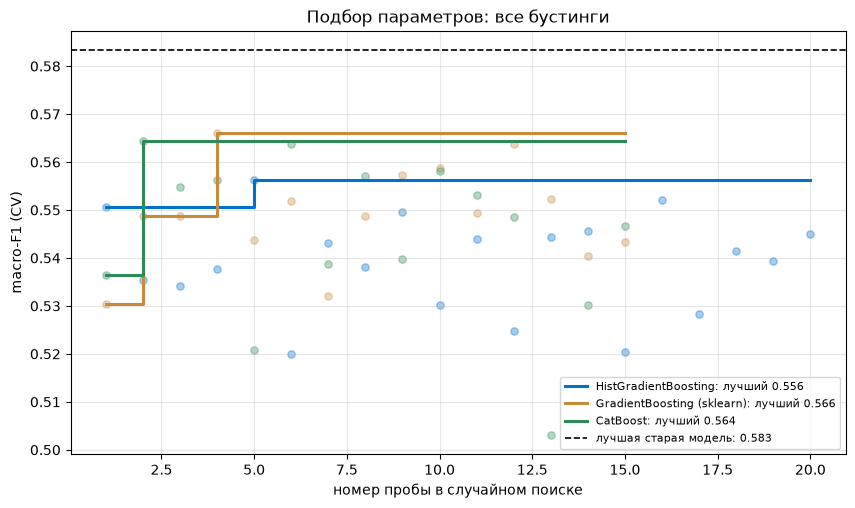

In [14]:
PALETTE = ["#0072CE", "#C98A3C", "#2E8B57", "#B03A48", "#7A4EAB"]

fig, ax = plt.subplots(figsize=(10, 5.5))
for (kind, (title, _)), color in zip(MODELS.items(), PALETTE):
    scores = searches[kind].cv_results_["mean_test_score"]
    trial = np.arange(1, len(scores) + 1)
    ax.scatter(trial, scores, color=color, alpha=0.35, s=28)
    ax.step(trial, np.maximum.accumulate(scores), where="post", color=color, lw=2.2, label=f"{title}: лучший {scores.max():.3f}")
ax.axhline(best_old_f1, color="black", ls="--", lw=1.2, label=f"лучшая старая модель: {best_old_f1:.3f}")
ax.set_xlabel("номер пробы в случайном поиске"); ax.set_ylabel("macro-F1 (CV)")
ax.set_title("Подбор параметров: все бустинги"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.savefig("results/gb_search.png", dpi=120, bbox_inches="tight")
plt.show()

## Шаг 3. Сколько деревьев и какой темп обучения

Для леса число деревьев выходило на плато. У бустинга качество сначала растёт, потом **падает**: лишние деревья подгоняют
модель под шум. Чем меньше темп обучения, тем позже достигается максимум. Берём параметры, найденные в шаге 2, и для каждой
модели строим качество на CV в зависимости от числа деревьев. Модель обучается один раз до максимума, а оценки на
меньшем числе деревьев берутся из «этапов» (`staged_predict`, у CatBoost — `ntree_end`). Берём **наименьшее** число деревьев
в пределах 0.002 от лучшего.

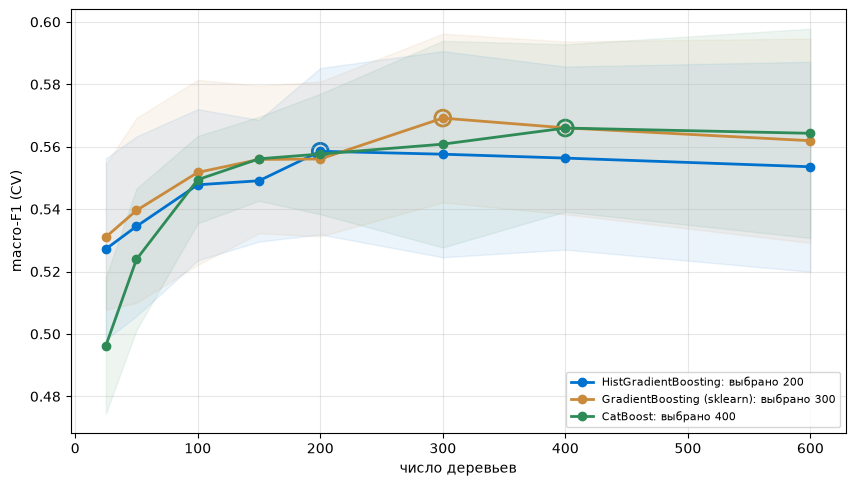

выбрано деревьев: {'HistGradientBoosting': 200, 'GradientBoosting (sklearn)': 300, 'CatBoost': 400}


,HistGradientBoosting,GradientBoosting (sklearn),CatBoost
деревьев,,,
25,0.527,0.531,0.496
50,0.534,0.540,0.524
100,0.548,0.552,0.549
150,0.549,0.556,0.556
200,0.559,0.556,0.558
300,0.558,0.569,0.561
400,0.556,0.566,0.566
600,0.554,0.562,0.564


In [15]:
SIZES = [25, 50, 100, 150, 200, 300, 400, 600]

curves, N_BEST = {}, {}
for kind, (title, _) in MODELS.items():
    params = {k: v for k, v in BEST[kind].items() if not k.endswith(TREES[kind])}
    pipe = build_pipeline(kind, **params, **{PREFIX[kind] + TREES[kind]: max(SIZES)})
    curves[kind] = bu.staged_macro_f1(pipe, X_train, y_train, folds, SIZES)
    mean = curves[kind].mean(axis=0)
    N_BEST[kind] = min(n for n, s in zip(SIZES, mean) if s >= mean.max() - 0.002)   # наименьшее n в пределах 0.002 от лучшего

fig, ax = plt.subplots(figsize=(10, 5.5))
for (kind, (title, _)), color in zip(MODELS.items(), PALETTE):
    mean, std = curves[kind].mean(axis=0), curves[kind].std(axis=0)
    ax.plot(SIZES, mean, marker="o", color=color, lw=2, label=f"{title}: выбрано {N_BEST[kind]}")
    ax.fill_between(SIZES, mean - std, mean + std, color=color, alpha=0.08)
    ax.scatter([N_BEST[kind]], [mean[SIZES.index(N_BEST[kind])]], s=130, facecolors="none", edgecolors=color, lw=2)
ax.set_xlabel("число деревьев"); ax.set_ylabel("macro-F1 (CV)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.savefig("results/gb_n_estimators.png", dpi=120, bbox_inches="tight")
plt.show()

print("выбрано деревьев:", {MODELS[k][0]: n for k, n in N_BEST.items()})
show_table(pd.DataFrame({MODELS[k][0]: curves[k].mean(axis=0) for k in MODELS}, index=pd.Index(SIZES, name="деревьев")))

**Темп обучения против числа деревьев.** На одной модели (`HistGradientBoosting`, остальные параметры — лучшие из шага 2)
видно главный компромисс бустинга: маленький темп требует много деревьев, большой быстро достигает пика и затем деградирует.

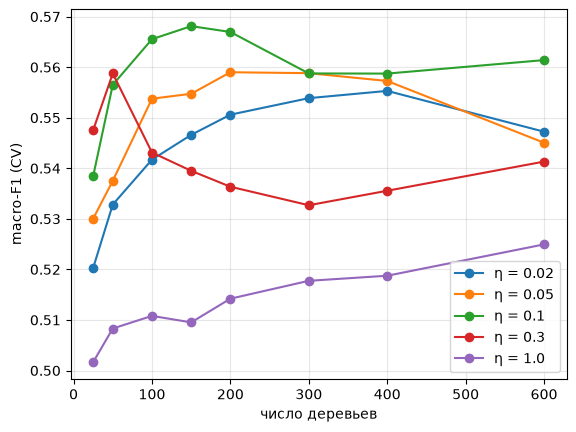

In [17]:
RATES = [0.02, 0.05, 0.1, 0.3, 1.0]
base = {k: v for k, v in BEST["hgb"].items() if not k.endswith(("max_iter", "learning_rate"))}
rate_curves = {}
for rate in RATES:
    pipe = build_pipeline("hgb", **base, gb__max_iter=max(SIZES), gb__learning_rate=rate)
    rate_curves[rate] = bu.staged_macro_f1(pipe, X_train, y_train, folds, SIZES).mean(axis=0)

for rate, curve in rate_curves.items():
    plt.plot(SIZES, curve, marker="o", label=f"η = {rate}")
plt.xlabel("число деревьев"); plt.ylabel("macro-F1 (CV)"); plt.grid(alpha=0.3); plt.legend()
plt.savefig("results/gb_learning_rate.png", dpi=120, bbox_inches="tight")
plt.show()

## Шаг 4. Итоговые модели

Для каждого бустинга: лучшие параметры из шага 2 и число деревьев из шага 3. Метрики на CV считаем так же, как у старых
моделей (все метрики из таблицы HW1), записываем строки в общую таблицу, обучаем на всём train и сохраняем
`artifacts/hw2_gb_hist.joblib`, `hw2_gb_sklearn` и `hw2_gb_catboost`.

*Оговорка:* параметры подбирались на этих же блоках, поэтому оценка слегка оптимистична. «Честная» оценка — test в конце.
*Заметка на будущее:* в HW1 вы писали, что для скрытого теста модели переобучаете на всех размеченных диалогах (train+test).
Для бустингов это можно сделать в самом конце, когда выбор модели закончен.
*Важно:* модель `hw2_gb_sklearn` содержит класс `BalancedFit` из `boosting_utils.py`, поэтому этот файл должен
лежать рядом с `solution_utils.py` и импортироваться при загрузке моделей.

In [ ]:
finals, final_rows = {}, {}
for kind, (title, file) in MODELS.items():
    params = {k: v for k, v in BEST[kind].items() if not k.endswith(TREES[kind])}
    params[PREFIX[kind] + TREES[kind]] = N_BEST[kind]
    model = build_pipeline(kind, **params)

    started = time.perf_counter()
    final_rows[kind] = su.cv_metrics(model, X_train, y_train, folds, n_jobs=1)
    history.append({"шаг": "2-3. подбор параметров и числа деревьев", "модель": title, **final_rows[kind],
                    "время, с": time.perf_counter() - started})

    cv_table = su.save_result("cv_table.csv", file, final_rows[kind])
    finals[kind] = model.fit(X_train, y_train)
    print("сохранено:", su.save_model(file, finals[kind]))

history_table = pd.DataFrame(history)
history_table.to_csv("results/gb_history.csv", index=False)
show_table(cv_table)     # общая таблица: старые модели, случайный лес и бустинги

сохранено: /home/diznak/Repositories/MIPT_ML_homework/solution_hw_2_BKZ/artifacts/hw2_gb_hist.joblib
сохранено: /home/diznak/Repositories/MIPT_ML_homework/solution_hw_2_BKZ/artifacts/hw2_gb_sklearn.joblib
сохранено: /home/diznak/Repositories/MIPT_ML_homework/solution_hw_2_BKZ/artifacts/hw2_gb_catboost.joblib


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
0,0.606,0.703,0.570,0.790,0.650,0.681,0.437,0.708,0.895,0.713,0.378
1,0.606,0.703,0.570,0.790,0.650,0.681,0.437,0.708,0.895,0.713,0.378
2,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
3,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
4,0.569,0.659,0.571,0.764,0.598,0.558,0.575,0.761,0.746,0.385,0.391
5,0.566,0.662,0.558,0.755,0.588,0.563,0.557,0.742,0.769,0.428,0.348
6,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
7,0.559,0.648,0.565,0.762,0.597,0.561,0.559,0.750,0.735,0.351,0.400
8,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
9,0.486,0.549,0.527,0.674,0.499,0.568,0.485,0.714,0.588,0.202,0.509


In [ ]:
best_old = cv_table[cv_table.index.str.startswith("hw1_")]["macro_f1"].max()
for kind, (title, _) in MODELS.items():
    gain = final_rows[kind]["macro_f1"] - best_old
    print(f"{title:36s} {final_rows[kind]['macro_f1']:.3f} | лучшая старая: {best_old:.3f} | разница: {gain:+.3f}")
best_kind = max(final_rows, key=lambda k: final_rows[k]["macro_f1"])
print("лучший бустинг на CV:", MODELS[best_kind][0])

HistGradientBoosting                 0.559 | лучшая старая: 0.583 | разница: -0.025
GradientBoosting (sklearn)           0.569 | лучшая старая: 0.583 | разница: -0.014
CatBoost                             0.566 | лучшая старая: 0.583 | разница: -0.017
лучший бустинг на CV: GradientBoosting (sklearn)


## Шаг 5. Важность признаков

У `GradientBoosting`, как у леса, есть MDI (`feature_importances_`): насколько признак в среднем уменьшал потери
в деревьях. У CatBoost — своя мера (`feature_importances_`: на сколько меняется ответ модели при разных значениях признака).
У `HistGradientBoosting` MDI нет, поэтому для него считаем **перестановочную важность** (на сколько падает macro-F1,
если перемешать признак) на отложенном блоке CV. Все важности нормированы на сумму 1, чтобы столбцы можно было сравнивать
(значения разных мер всё равно не идентичны; смотрите на порядок признаков).
Признаки SVD — это «темы», а не слова; их важность лучше смотреть суммой по группе (вторая таблица).

In [ ]:
from sklearn.inspection import permutation_importance

importance = {}
for kind, (title, _) in MODELS.items():
    model = finals[kind]
    if kind == "hgb":                                  # у HistGB нет MDI: перестановочная важность на отложенном блоке
        train_part, valid_part = folds[0]
        features = clone(model[:-1]).fit(X_train.iloc[train_part], y_train[train_part])
        classifier = clone(model[-1]).fit(features.transform(X_train.iloc[train_part]), y_train[train_part])
        permuted = permutation_importance(classifier, features.transform(X_train.iloc[valid_part]), y_train[valid_part],
                                          scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=1)
        values = np.clip(permuted.importances_mean, 0, None)
        names = features.get_feature_names_out()
    else:
        values = np.asarray(model.named_steps["gb"].feature_importances_, dtype=float)
        names = model.named_steps["features"].get_feature_names_out()
    importance[title] = pd.Series(values / values.sum(), index=names)

importance_table = pd.DataFrame(importance)
importance_table.to_csv("results/gb_importance.csv")
best_title = MODELS[best_kind][0]
show_table(importance_table.sort_values(best_title, ascending=False).head(15))

,HistGradientBoosting,GradientBoosting (sklearn),CatBoost
all_tfidf__truncatedsvd1,0.009,0.034,0.026
last_tfidf__truncatedsvd19,0.000,0.032,0.020
numeric__has_assistant_code,0.000,0.029,0.022
all_tfidf__truncatedsvd6,0.000,0.029,0.024
all_tfidf__truncatedsvd3,0.053,0.028,0.016
last_tfidf__truncatedsvd4,0.018,0.027,0.019
last_tfidf__truncatedsvd1,0.093,0.025,0.012
last_tfidf__truncatedsvd13,0.000,0.023,0.019
all_tfidf__truncatedsvd2,0.000,0.019,0.017
all_tfidf__truncatedsvd4,0.000,0.019,0.015


In [ ]:
group_names = {"all_tfidf": "текст всех реплик (SVD)", "last_tfidf": "последняя реплика (SVD)", "numeric": "числовые признаки"}
groups = importance_table.groupby(importance_table.index.str.split("__").str[0]).sum().rename(index=group_names)
show_table(groups)

,HistGradientBoosting,GradientBoosting (sklearn),CatBoost
текст всех реплик (SVD),0.630,0.688,0.731
последняя реплика (SVD),0.304,0.220,0.178
числовые признаки,0.067,0.092,0.091


## Шаг 6. Test — запускать один раз

Test нельзя использовать для выбора параметров. Эту ячейку запускаем **один раз**, когда модели окончательно готовы.

In [ ]:
from sklearn.metrics import confusion_matrix

test_probas = {}
for kind, (title, file) in MODELS.items():
    test_probas[kind] = finals[kind].predict_proba(X_test)
    test_table = su.save_result("test_table.csv", file, su.all_metrics(y_test, test_probas[kind]))
display(show_table(test_table))

test_pred = finals[best_kind].classes_[test_probas[best_kind].argmax(axis=1)]
print("матрица ошибок лучшего по CV бустинга:", MODELS[best_kind][0])
show_table(pd.DataFrame(confusion_matrix(y_test, test_pred, labels=CLASSES),
                        index=[f"факт {c}" for c in CLASSES], columns=[f"предсказано {c}" for c in CLASSES]), axis=None)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
0,0.614,0.715,0.581,0.798,0.644,0.731,0.441,0.717,0.899,0.636,0.404
1,0.614,0.715,0.581,0.798,0.644,0.731,0.441,0.717,0.899,0.636,0.404
2,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
3,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
4,0.590,0.679,0.585,0.749,0.607,0.590,0.547,0.749,0.783,0.449,0.423
5,0.587,0.667,0.600,0.754,0.612,0.570,0.547,0.765,0.752,0.400,0.500
6,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
7,0.553,0.640,0.563,0.737,0.593,0.541,0.514,0.739,0.732,0.359,0.442
8,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
9,0.473,0.524,0.544,0.696,0.532,0.554,0.486,0.720,0.530,0.190,0.615


матрица ошибок лучшего по CV бустинга: GradientBoosting (sklearn)


,предсказано negative,предсказано neutral,предсказано positive
факт negative,98,66,15
факт neutral,64,267,24
факт positive,10,16,26
